#### Geospatial data from open sources

Querying points of interest (POIs) using Overpass API of OSM's querying API. This is incredibly powerful that it can quickly return queried features and allows fir selection of location, tags, proximity and more.

In [ ]:
!pip install overpass > /dev/null

In [ ]:
import overpass
api = overpass.API()
# look for restaurants in within 1500m in NYC area
overpass_query= """
(node['amenity'='restaurant'](around:1500, 40.766876, -73.979076);
 way['amenity'='restaurant'](around:1500, 40.766876, -73.979076);
 rel['amenity'='restaurant'](around:1500, 40.766876, -73.979076);
);
out center;
"""
restaurants = api.get(overpass_query)

Fetching OpenStreetMap data using osmnx

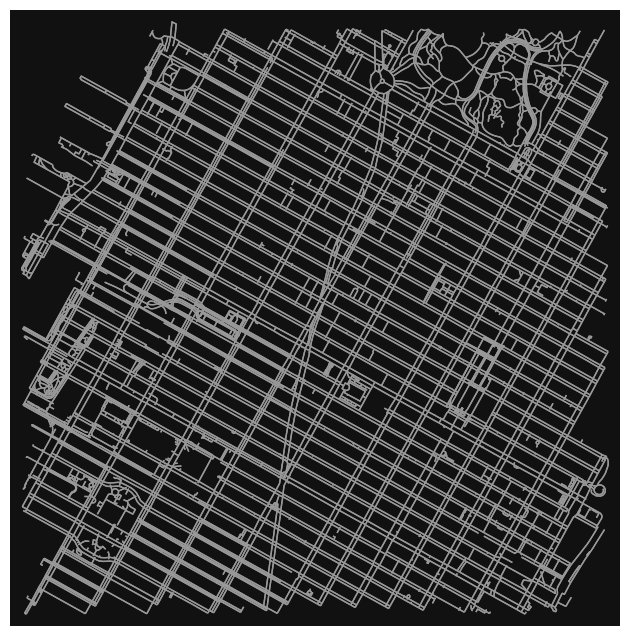

In [ ]:
import osmnx as ox
# fetch OSM street network (drive, walk, private) from location
place_name = "Times Square, NY"
graph = ox.graph_from_address(place_name, network_type='walk', dist=1500)
fig, ax = ox.plot_graph(graph, figsize=(8,8), node_size=0)

In [ ]:
nodes, edges = ox.graph_to_gdfs(graph)

In [ ]:
ox.basic_stats(graph)

{'n': 5335,
 'm': 16514,
 'k_avg': 6.190815370196813,
 'edge_length_total': 697986.2573237077,
 'edge_length_avg': 42.26633506865131,
 'streets_per_node_avg': 3.145079662605436,
 'streets_per_node_counts': {0: 0, 1: 943, 2: 0, 3: 1756, 4: 2612, 5: 24},
 'streets_per_node_proportions': {0: 0.0,
  1: 0.1767572633552015,
  2: 0.0,
  3: 0.32914714151827557,
  4: 0.48959700093720715,
  5: 0.004498594189315839},
 'intersection_count': 4392,
 'street_length_total': 348993.1286618563,
 'street_segment_count': 8257,
 'street_length_avg': 42.2663350686516,
 'circuity_avg': 1.0189640347513804,
 'self_loop_proportion': 0.0009688748940293085}

Circuitry average is the sum of edge length divided by the sum of straight line distances. It gives a metric > 1 that indicates how direct the network is (how much more distance is required when travelling via the graph as opposed to walking in a straight line  

In [ ]:
# osmnx expects an undirected graph
undirected_graph = graph.to_undirected()
ox.stats.circuity_avg(undirected_graph)

1.0213545553903534

/tmp/ipykernel_1070/3027453784.py:2: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  convex_hull = edges.unary_union.convex_hull


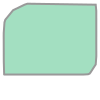

In [ ]:
# extended and density stats
convex_hull = edges.unary_union.convex_hull
convex_hull

##### CRS Projection of the graph



In [ ]:
edges.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
merc_edges = edges.to_crs(epsg=3857)
merc_nodes = nodes.to_crs(epsg=3857)
merc_edges.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

#### Shortest Path Analysis

Find the closest nodes in the network to our starting and ending locations

In [ ]:
!pip install ipyleaflet > /dev/null

In [ ]:
from ipyleaflet import *

# NYC
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)

map_ = Map(center=center, zoom=15)
map_.add_layer(Marker(location=source_point, icon=AwesomeIcon(name='camera', marker_color='red')))
map_.add_layer(Marker(location=destination_point, icon=AwesomeIcon(name='university', marker_color='green')))
map_.add_layer(Marker(location=center, icon=AwesomeIcon(name='graduation-cap')))

In [ ]:
# convert map_ from ipyleaflet to folium
import folium
map__ = folium.Map(location=center, zoom_start=14)
folium.Marker(location=source_point, icon=folium.Icon(color='red')).add_to(map__)
folium.Marker(location=destination_point, icon=folium.Icon(color='green')).add_to(map__)
folium.Marker(location=center, icon=folium.Icon(color='blue')).add_to(map__)
map__

Now back to out shortest path problem

In [ ]:
!pip install geopandas > /dev/null

In [ ]:
import geopandas

In [ ]:
'''
X = ox.distance.nearest_nodes(graph, source_point[1], source_point[0])
Y = ox.distance.nearest_nodes(graph, destination_point[1], destination_point[0])
closest_nodes = (X, Y)
closest_rows = nodes.loc(closest_nodes)
'''
X = [source_point[1], destination_point[1]]
Y = [source_point[0], destination_point[0]]
closest_nodes = ox.distance.nearest_nodes(graph, X, Y)

# rows from the node GeoDataFrame
closest_rows = nodes.loc[closest_nodes]

# put the two nodes into a GeoDataFrame
od_nodes = geopandas.GeoDataFrame(closest_rows, geometry='geometry', crs=nodes.crs)
od_nodes

,y,x,highway,street_count,railway,ref,geometry
osmid,,,,,,,
42423677,40.767686,-73.978591,NaN,3,NaN,NaN,POINT (-73.97859 40.76769)
42423844,40.758815,-73.998772,NaN,1,NaN,NaN,POINT (-73.99877 40.75881)


In [ ]:
!pip install networks[default] > /dev/null

In [ ]:
import networkx

shortest_route = networkx.shortest_path(graph, source=closest_nodes[0], target=closest_nodes[1], weight='length')
print(shortest_route)

[np.int64(42423677), 42424609, 1420632733, 4347550049, 4347550070, 4347550075, 4347550056, 7573557749, 7573557752, 10036554276, 10183983980, 8780665827, 8780665842, 4347550062, 10183978906, 8780665846, 10075114641, 10674102217, 11945388422, 10075114642, 10075114643, 10075114644, 10047471393, 10082533438, 10082615954, 10082649540, 10082707745, 10083914675, 10084871499, 10084983282, 10084983283, 10085060430, 10085099818, 10085663263, 10085663265, 10090624433, 10085839200, 10093892513, 3463815148, 11747170470, 10171089673, 10171089671, 10171089656, 10171089657, 10171089666, 10171089663, 8646554906, 8646554905, 10168047565, 10168047564, 10168047573, 10168047579, 10168047520, 10168047518, 10168047532, 10168047533, 10168047526, 9535571851, 10171120542, 10613636823, 10171120537, 10171120543, 10171120538, 10168212453, 10169614501, 10169614504, 10169614498, 10169614506, 8288270419, 8288270418, 8288270425, 593920840, 427804105, np.int64(42423844)]


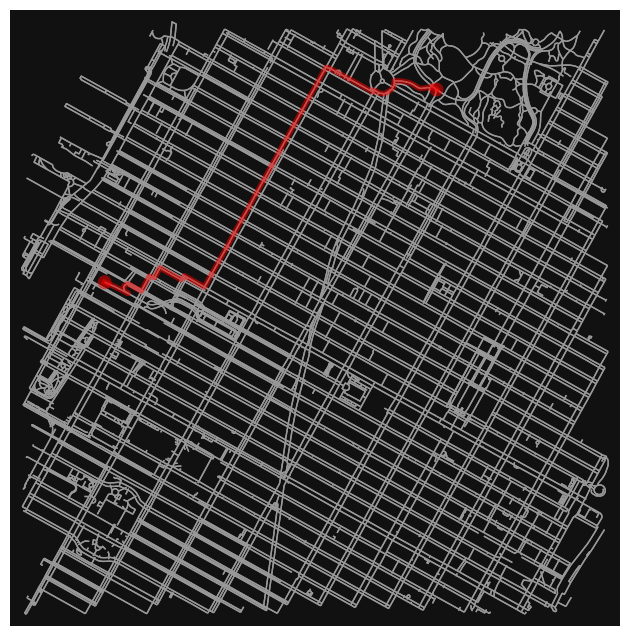

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [ ]:
ox.plot_graph_route(graph, shortest_route, figsize=(8,8), node_size=0)

Get the node list from the shortest route, create geometry from it, visualize bldgs footprint, street network and shortest route.

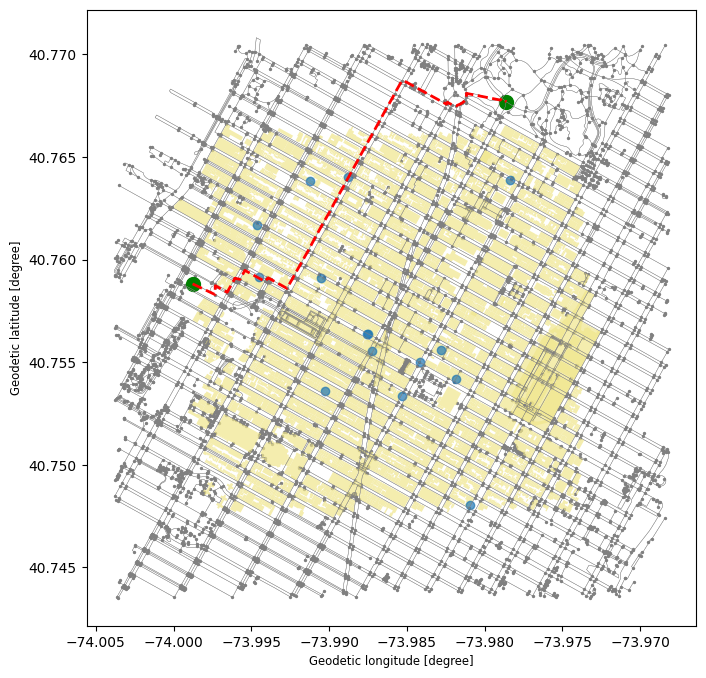

In [ ]:
from shapely.geometry import LineString

# nodes of the shortest path
route_nodes = nodes.loc[shortest_route]

# convert the nodes into a line geometry
route_line = LineString(route_nodes['geometry'].values)

# GeoDataFrame from the line
route_geom = geopandas.GeoDataFrame(geometry=[route_line], crs=nodes.crs)

# plot nodes and edges
ax = edges.plot(linewidth=0.25, color='gray', figsize=(8,8))
ax = nodes.plot(ax=ax, markersize=2, color='gray')

# add building footprints
ax = blds.plot(ax=ax, facecolor='khaki', alpha=0.7)

# add the shortest route
ax = route_geom.plot(ax=ax, linewidth=2, linestyle='--', color='red')

# highlight the start and end nodes
ax = od_nodes.plot(ax=ax, markersize=100, color='green')

#### Appendix

Graph and Mapping libraries

osmnx library for retrieving and manipulating data from OpenStreetMap.
Download data from OSM and return it as a networkx graph data structure.

In [ ]:
!pip install osmnx > /dev/null

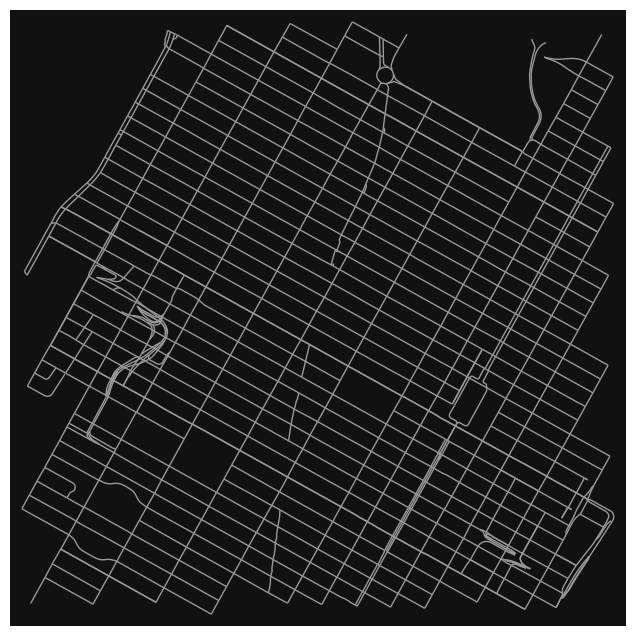

In [ ]:
import osmnx as ox
place_name = "Times Square, NY"
# Since Times Square is a landmark rather than an administrative area,
# we retrieve the network within a buffer (e.g., 500 meters) around its address.
graph = ox.graph_from_address(place_name, dist=1500, network_type='drive')
# plot the graphs
fig, ax = ox.plot_graph(graph, figsize=(8, 8), node_size=0)

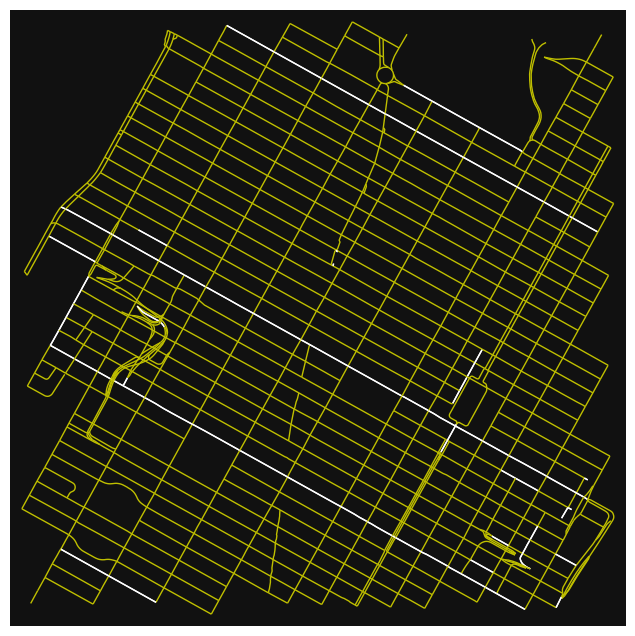

In [ ]:
# highlight all one way edges
#ec = ox.plot.get_edge_colors_by_attr(graph, 'oneway', cmap='coolwarm')
ec = ['y' if data['oneway'] else 'w' for u, v, key, data in graph.edges(keys=True, data=True)]
fig, ax = ox.plot_graph(graph, figsize=(8, 8), node_size=0, edge_color=ec)

In [ ]:
nodes, edges = ox.graph_to_gdfs(graph)
print(type(graph))
nodes.head(1),

<class 'networkx.classes.multidigraph.MultiDiGraph'>


(                  y          x          highway  street_count  ref  \
 osmid                                                                
 42421969  40.769296 -73.981059  traffic_signals             3  NaN   
 
                            geometry  
 osmid                                
 42421969  POINT (-73.98106 40.7693)  ,)

In [ ]:
edges.head(1),

(                             osmid    highway lanes maxspeed  \
 u        v          key                                        
 42421969 5706568625 0    709355577  secondary     2   25 mph   
 
                                       name  oneway reversed     length  \
 u        v          key                                                  
 42421969 5706568625 0    Central Park West    True    False  79.923653   
 
                                                                   geometry  \
 u        v          key                                                      
 42421969 5706568625 0    LINESTRING (-73.98106 40.7693, -73.98101 40.76...   
 
                         access width bridge tunnel  ref junction  
 u        v          key                                           
 42421969 5706568625 0      NaN   NaN    NaN    NaN  NaN      NaN  ,)

In [ ]:
# examine each individual node or edge
list(graph.nodes(data=True))[5]

(42423674,
 {'y': 40.766876,
  'x': -73.979076,
  'highway': 'traffic_signals',
  'street_count': 3})

In [ ]:
print(ox.basic_stats(graph))

{'n': 646, 'm': 1223, 'k_avg': 3.7863777089783284, 'edge_length_total': 152656.6120001279, 'edge_length_avg': 124.8214325430318, 'streets_per_node_avg': 3.710526315789474, 'streets_per_node_counts': {0: 0, 1: 9, 2: 2, 3: 163, 4: 465, 5: 7}, 'streets_per_node_proportions': {0: 0.0, 1: 0.01393188854489164, 2: 0.0030959752321981426, 3: 0.25232198142414863, 4: 0.7198142414860681, 5: 0.010835913312693499}, 'intersection_count': 637, 'street_length_total': 140943.58015542687, 'street_segment_count': 1145, 'street_length_avg': 123.09482983006714, 'circuity_avg': 1.0079710361591, 'self_loop_proportion': 0.0}


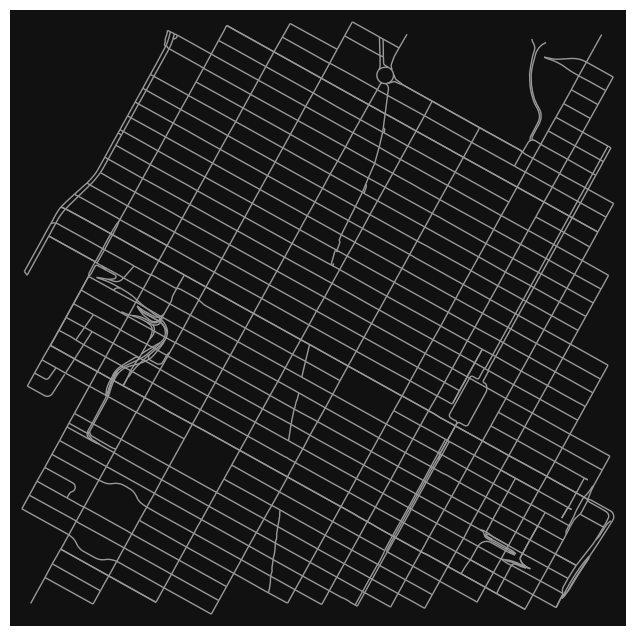

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [ ]:
# GeoDataFrame to MultiDiGraph
G = ox.graph_from_gdfs(nodes, edges)
ox.plot_graph(G, figsize=(8, 8), node_size=0)

Visualization using folium

In [ ]:
import geopandas as gpd
import folium

In [ ]:
# Plot the Times Square graph on an interactive folium map using OSMnx's built-in folium utility
# First, let's find the centroid of our nodes to center our folium map
nodes_proj, edges_proj = ox.graph_to_gdfs(graph)
mean_lat = nodes_proj['y'].mean()
mean_lng = nodes_proj['x'].mean()

# Create a folium map (using OpenStreetMap default tiles to avoid CartoDB API key warnings)
m = folium.Map(location=[mean_lat, mean_lng], zoom_start=15, tiles='OpenStreetMap')

# Add the edges of our graph to the folium map
# We iterate through the edges GeoDataFrame to draw lines on the map
for _, row in edges_proj.iterrows():
    if row['geometry'].geom_type == 'LineString':
        # Folium coordinates are in (latitude, longitude) format, so we reverse the (x, y) coordinates from geom
        coords = [(y, x) for x, y in row['geometry'].coords]
        folium.PolyLine(coords, color='blue', weight=2, opacity=0.7).add_to(m)

# Display the map
m

Regional Resources: NYC and Surrounding Suburbs

Define a dataset of major resource hubs across the NYC metropolitan area, including Long Island, Westchester, and Northern New Jersey.

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# Define key regional resources in NYC and its major suburbs
regional_resources = {
    'Manhattan Hub (NYC)': (40.7580, -73.9855, 'Urban Core'),
    'Brooklyn Depot (NYC)': (40.6500, -74.0000, 'Urban Core'),
    'Queens Logistics (NYC)': (40.7711, -73.8740, 'Urban Core'),
    'Hicksville Hub (Long Island)': (40.7675, -73.5244, 'Suburb East'),
    'White Plains Center (Westchester)': (41.0340, -73.7629, 'Suburb North'),
    'Newark Airport Hub (North Jersey)': (40.6895, -74.1745, 'Suburb West'),
    'Stamford Station (Fairfield CT)': (41.0470, -73.5388, 'Suburb North-East')
}

# Construct regional GeoDataFrame
geom_resources = [Point(lon, lat) for name, (lat, lon, zone) in regional_resources.items()]
df_resources = gpd.GeoDataFrame({
    'Location': list(regional_resources.keys()),
    'Zone': [zone for lat, lon, zone in regional_resources.values()]
}, geometry=geom_resources, crs="EPSG:4326")

# Project to NY State Plane (EPSG:2263) for accurate suburban scale mapping
df_resources_proj = df_resources.to_crs(epsg=2263)

# Display the structured resource locations
display(df_resources_proj)

,Location,Zone,geometry
0,Manhattan Hub (NYC),Urban Core,POINT (988267.074 215436.879)
1,Brooklyn Depot (NYC),Urban Core,POINT (984250 176088.908)
2,Queens Logistics (NYC),Urban Core,POINT (1019150.112 220234.408)
3,Hicksville Hub (Long Island),Suburb East,POINT (1115990.593 219255.345)
4,White Plains Center (Westchester),Suburb North,POINT (1049663.827 316083.295)
5,Newark Airport Hub (North Jersey),Suburb West,POINT (935856.907 190528.081)
6,Stamford Station (Fairfield CT),Suburb North-East,POINT (1111465.696 321066.24)


Visualizing the NYC Metropolitan Area and Suburban Hubs.
Plot regional resource centers, using color-coded categories to differentiate the urban core of NYC from the suburban commuter hubs.

In [ ]:
import matplotlib.pyplot as plt

# Set up a clean, professional visualization for NYC and its suburbs
fig, ax = plt.subplots(figsize=(10, 8))

# Custom color mapping for zones
zone_colors = {
    'Urban Core': '#e63946',       # Crimson/Red for NYC Core
    'Suburb East': '#f4a261',      # Orange/Sandy for Long Island
    'Suburb North': '#2a9d8f',     # Teal/Green for Westchester
    'Suburb West': '#457b9d',      # Muted Blue for New Jersey
    'Suburb North-East': '#a8dadc' # Light Blue for Connecticut
}

# Extract projected coordinates
x_res = df_resources_proj.geometry.x
y_res = df_resources_proj.geometry.y

# Plot hubs categorized by zone
for zone, color in zone_colors.items():
    sub_df = df_resources_proj[df_resources_proj['Zone'] == zone]
    if not sub_df.empty:
        ax.scatter(sub_df.geometry.x, sub_df.geometry.y,
                   s=350, color=color, label=zone,
                   edgecolors='black', linewidth=1.5, alpha=0.85)

# Label each location clearly
for idx, row in df_resources_proj.iterrows():
    ax.annotate(row['Location'],
                (row.geometry.x, row.geometry.y),
                textcoords="offset points",
                xytext=(0, 15),
                ha='center',
                fontsize=9,
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.5, alpha=0.8))

ax.set_title("NYC Metro and Surrounding Suburbs\nProjected Coordinate Map (EPSG:2263)")
ax.legend(title="Region Zone", loc='lower right', frameon=True, shadow=True)
ax.set_axis_off()

# Adjust limits to include all suburbs comfortably
ax.set_xlim(x_res.min() - 60000, x_res.max() + 60000)
ax.set_ylim(y_res.min() - 60000, y_res.max() + 60000)

plt.tight_layout()
plt.show()